# Group 27 - EDA Draft (Maria): Member profile and descriptive analysis
 The goal of this notebook is to build a descriptive profile of the ACDC coworking members, using the already cleaned dataset. We want to understand who the members are, which plans they choose, how membership has evolved over the 3 years, and how the main variables relate to each other.

*Beyond the labs:* the date tools (`.dt`, `to_period`, `period_range`) are not used in the lab solutions. The other methods follow labs 03 to 06.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 2. Reading the cleaned data

In [2]:
df_clean = pd.read_csv(
    "../../data/acdc_clean.csv", sep=";",
    parse_dates=["membership_start", "membership_end", "last_badge_swipe"]
)
df = df_clean.copy()
print(df.shape)

(15108, 32)


## 3. Initial Analysis of the cleaned data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15108 entries, 0 to 15107
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   member_id                    15108 non-null  object        
 1   age                          15108 non-null  float64       
 2   gender                       15108 non-null  object        
 3   industry                     15108 non-null  object        
 4   country                      15108 non-null  object        
 5   is_team_account              15108 non-null  bool          
 6   n_colleagues_on_account      15108 non-null  float64       
 7   plan_tier                    15108 non-null  object        
 8   plan_days_per_week           15108 non-null  int64         
 9   membership_start             15108 non-null  datetime64[ns]
 10  membership_end               11206 non-null  datetime64[ns]
 11  last_badge_swipe             15108 non-nu

From the 32 columns, only membership_end has null values. This is expected: an empty end date means that the membership is still active, as shown in the cleaning notebook.


In [4]:
metric_features = df.select_dtypes(include="number").columns.tolist()
# dates are neither metric nor non-metric features, so they stay out of both lists
non_metric_features = [c for c in df.select_dtypes(exclude=["number", "datetime"]).columns
                       if c != "member_id"]
print(metric_features)
print(non_metric_features)

['age', 'n_colleagues_on_account', 'plan_days_per_week', 'days_since_last_visit', 'total_visits', 'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period', 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued', 'n_renewals', 'lifetime_value']
['gender', 'industry', 'country', 'is_team_account', 'plan_tier', 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'ltv_imputed']


In [5]:
# so that the plots always follow the same order, from the cheapest plan to the most expensive
p_order = ["hot_desk", "flex", "full_time", "dedicated_desk", "private_office"]
print(df["plan_tier"].unique())


['hot_desk' 'flex' 'dedicated_desk' 'full_time' 'private_office']


In order to have always the same order, from least expensive to the most expensive.

## 4. Customer Demographics

### 4.1. Age

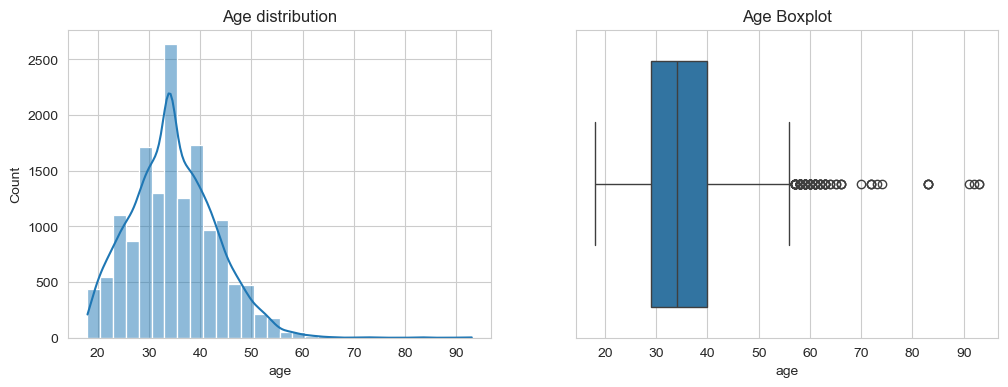

count    15108.000000
mean        34.723061
std          8.211885
min         18.000000
25%         29.000000
50%         34.000000
75%         40.000000
max         93.000000
Name: age, dtype: float64
Skewness: 0.46
Members aged 34, original data: 710 | cleaned data: 1371


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["age"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age distribution")
sns.boxplot(x=df["age"], ax=axes[1])
axes[1].set_title("Age Boxplot")
plt.show()

print(df["age"].describe())
print("Skewness:", round(df["age"].skew(), 2))

# how many ages of 34 come from the cleaning? (it replaced missing and invalid ages by the median)
raw_ages = pd.read_csv("../../data/acdc_dataset.csv", sep=";").drop_duplicates()["age"]
print("Members aged 34, original data:", (raw_ages == 34).sum(), "| cleaned data:", (df["age"] == 34).sum())

The mean and median are almost the same and the distribution is only slightly skewed to the right (skewness of 0.46).

The interquartile range goes from 29 to 40 years, which means that half of the customers are in this range. 34 is the most common age, but this is partly an effect of the cleaning: missing and invalid ages were replaced by the median, which almost doubles the number of members aged 34.

75% of the members are 40 or younger. The age of 93 is the furthest outlier, which doesn't seem very plausible in this context.

### 4.2. Gender, Industry, Country

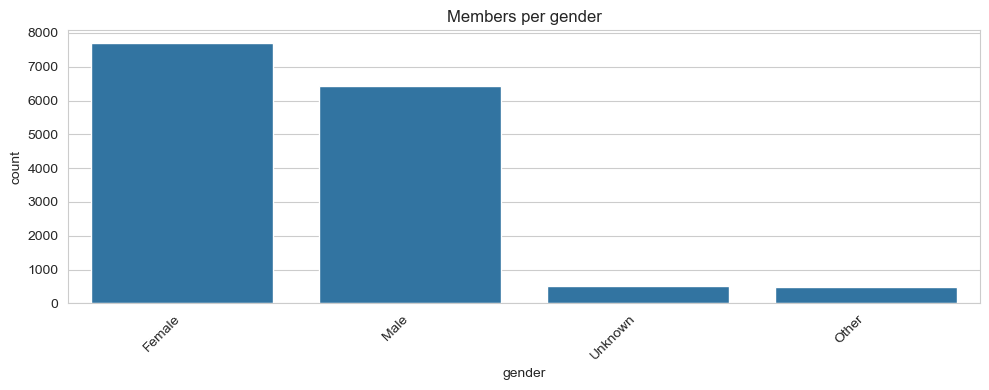

gender
Female     0.509
Male       0.425
Unknown    0.034
Other      0.032
Name: proportion, dtype: float64


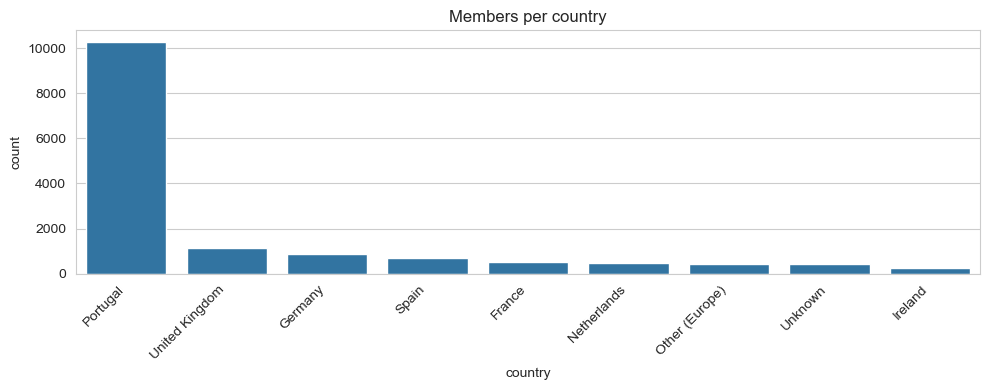

country
Portugal          0.680
United Kingdom    0.076
Germany           0.058
Spain             0.047
France            0.035
Netherlands       0.032
Other (Europe)    0.029
Unknown           0.027
Ireland           0.016
Name: proportion, dtype: float64


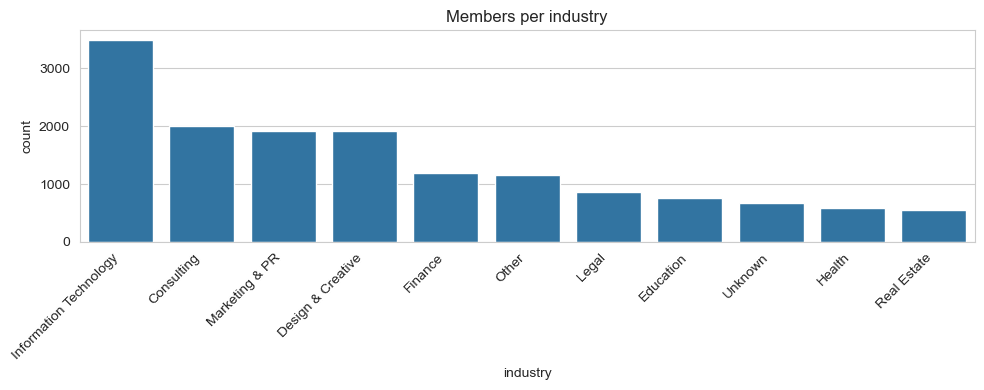

industry
Information Technology    0.231
Consulting                0.133
Marketing & PR            0.127
Design & Creative         0.127
Finance                   0.079
Other                     0.077
Legal                     0.057
Education                 0.050
Unknown                   0.044
Health                    0.038
Real Estate               0.036
Name: proportion, dtype: float64


In [7]:
for col in ["gender", "country", "industry"]:
    plt.figure(figsize=(10, 4))
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order)
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Members per {col}")
    plt.tight_layout()
    plt.show()
    print(df[col].value_counts(normalize=True).round(3))

There's a small feminine majority.

Portugal is clearly the most common country which makes sense.

The biggest industry is Information Technology with almost twice as the next, Consulting.

### 4.3 Lifetime Value, Visits and Age by Plan Tier

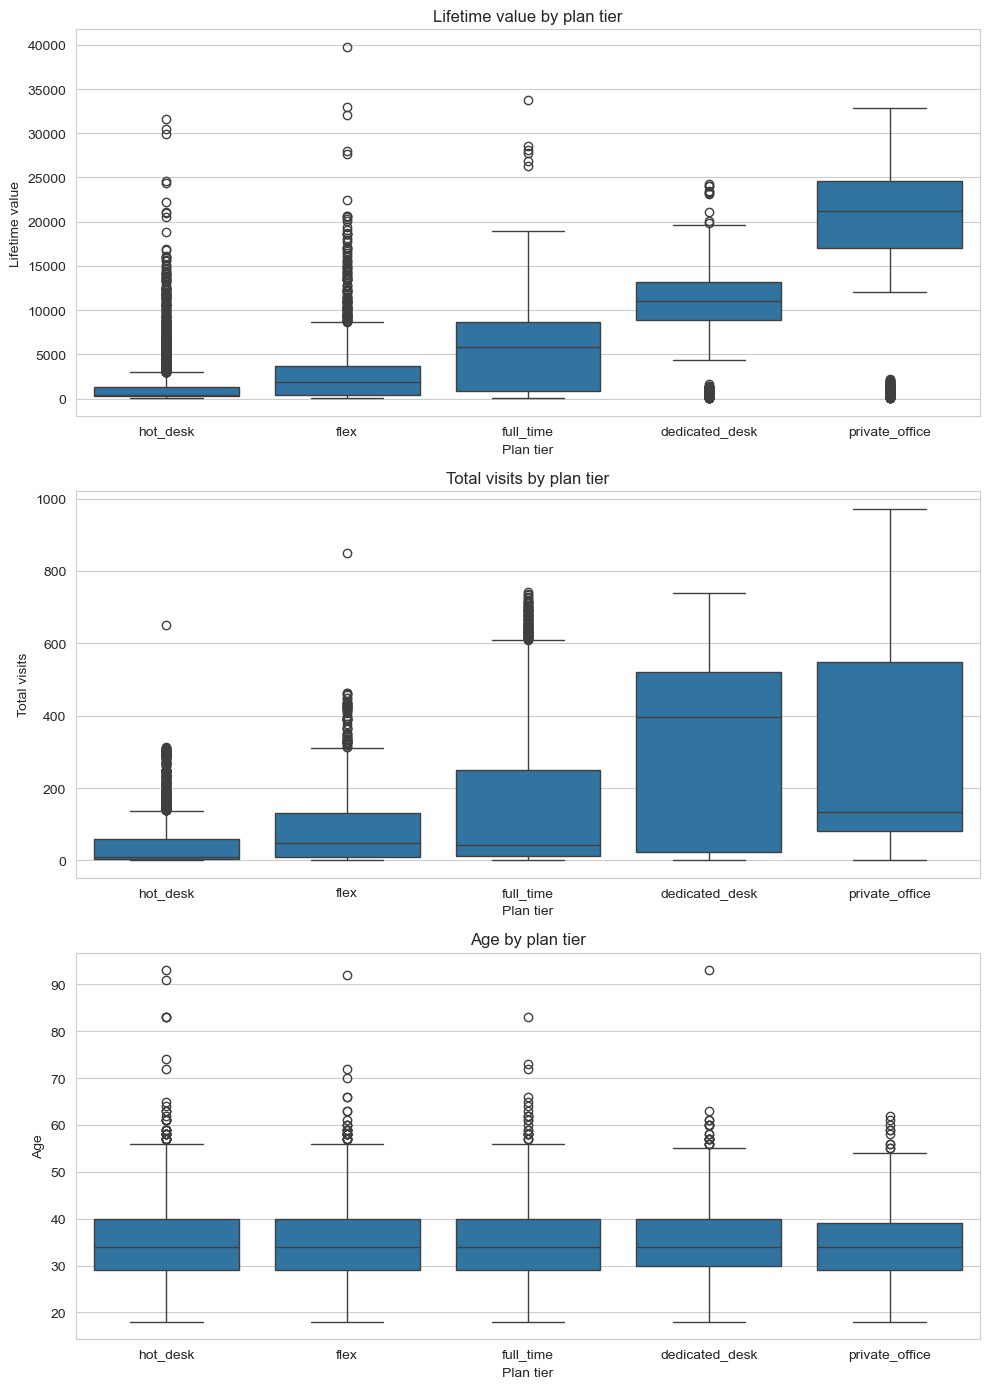

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 14))

for ax, col, label in zip(axes,
                          ["lifetime_value", "total_visits", "age"],
                          ["Lifetime value", "Total visits", "Age"]):
    sns.boxplot(data=df, x="plan_tier", y=col, order=p_order, ax=ax)
    ax.set_title(f"{label} by plan tier")
    ax.set_xlabel("Plan tier")
    ax.set_ylabel(label)

plt.tight_layout()
plt.show()

In [9]:
print(df.groupby("plan_tier")[["lifetime_value", "total_visits", "age"]]
        .median().loc[p_order].round(1))

                lifetime_value  total_visits   age
plan_tier                                         
hot_desk                 357.2          10.0  34.0
flex                    1847.8          47.0  34.0
full_time               5868.5          42.0  34.0
dedicated_desk         11045.8         396.0  34.0
private_office         21161.2         133.0  34.0


- Lifetime value rises with plan tier, from about 360 in hot desk to 21 200 in private office.
- As for visits the median peaks at dedicated desk (396) and drops to 133 in private office.
- The age is identical trough all plans, with a median of 34.

### 4.4. Plan and Account

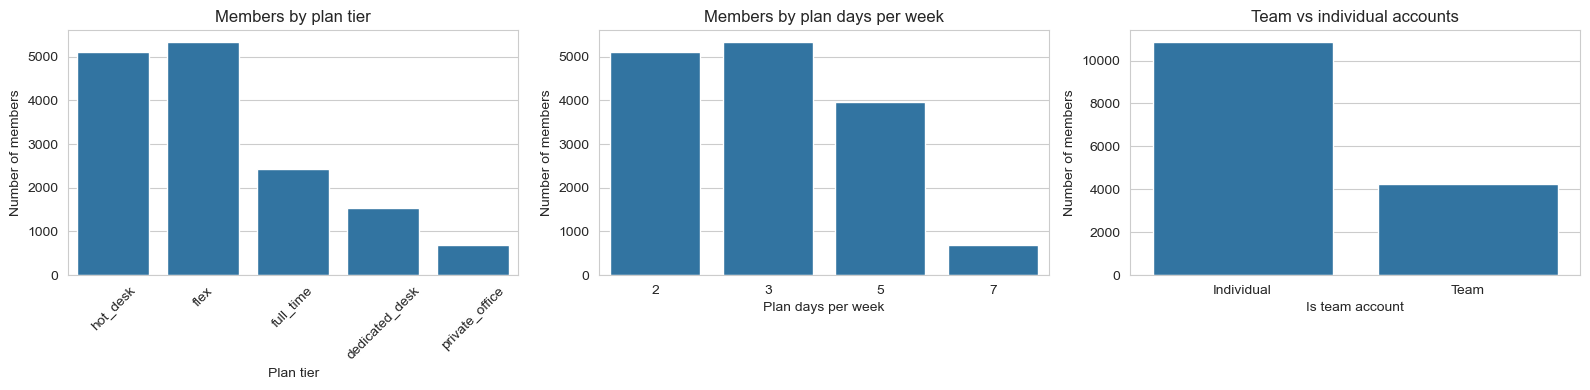

In [10]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=df, x="plan_tier", order=p_order, ax=axes[0])
axes[0].set_title("Members by plan tier")
axes[0].set_xlabel("Plan tier")
axes[0].set_ylabel("Number of members")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=df, x="plan_days_per_week", ax=axes[1])
axes[1].set_title("Members by plan days per week")
axes[1].set_xlabel("Plan days per week")
axes[1].set_ylabel("Number of members")

sns.countplot(data=df, x="is_team_account", ax=axes[2])
axes[2].set_title("Team vs individual accounts")
axes[2].set_xlabel("Is team account")
axes[2].set_ylabel("Number of members")
axes[2].set_xticks([0, 1], ["Individual", "Team"])

plt.tight_layout()
plt.show()

The most frequent plans are flex and hot_desk, and the rarest is private_office, as expected.
The plan days per week follow the plans: 3 and 2 days are the most frequent, followed by 5 days, with 7 days the rarest.

Most of the customers have an individual account.


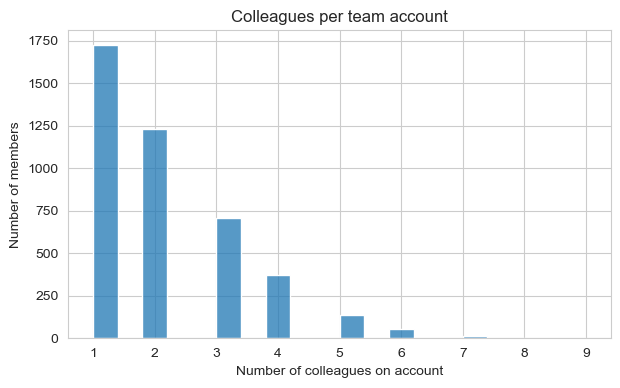

count    4248.000000
mean        2.104755
std         1.232782
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: n_colleagues_on_account, dtype: float64
Team members: 4248 (28.1% of the members)
{1.0: 0.406, 2.0: 0.29, 3.0: 0.167}


In [11]:
team = df[df["is_team_account"]]

plt.figure(figsize=(7, 4))
sns.histplot(team["n_colleagues_on_account"], bins=20)
plt.title("Colleagues per team account")
plt.xlabel("Number of colleagues on account")
plt.ylabel("Number of members")
plt.show()

print(team["n_colleagues_on_account"].describe())
print("Team members:", len(team), f"({len(team) / len(df):.1%} of the members)")
print(team["n_colleagues_on_account"].value_counts(normalize=True).sort_index().round(3).head(3).to_dict())

There are 4248 members in team accounts, about 28% of the customers.
The most common case is 1 colleague per team account (which means a team account of 2), and the median is 2 colleagues.

## 5. Time trends

### 5.1. New members per month

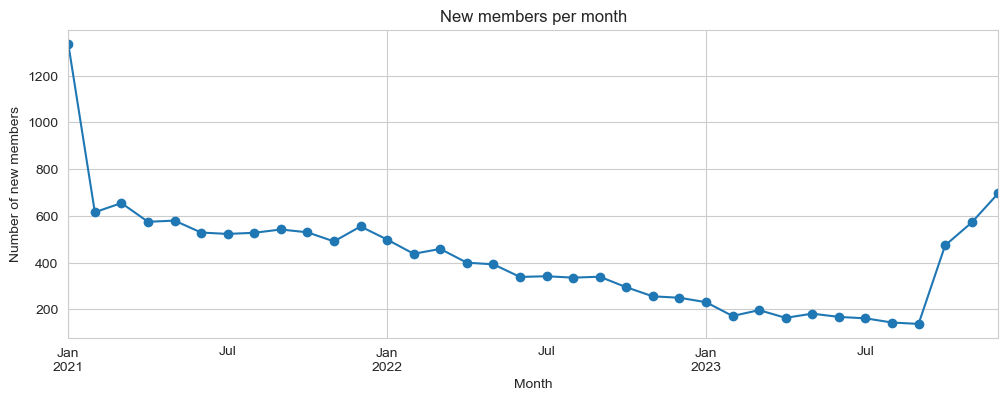

In [12]:
new_per_month = df.groupby(df["membership_start"].dt.to_period("M")).size()

new_per_month.plot(figsize=(12, 4), marker="o")
plt.title("New members per month")
plt.xlabel("Month")
plt.ylabel("Number of new members")
plt.show()

It is very visible that the month with the most new members is January 2021. It may be the start of the observation window: members who already existed before were probably recorded with a start date in that month. If so, they are not real new clients.

There's a gradual fall from early 2021 to September 2023, from about 600 to fewer than 200 new members per month.

Finally, there's a rise in the last 3 months of 2023, reaching almost 700 new members in December. It could be related to a successful campaign, but the data does not show the cause, so this is only a hypothesis.

### 5.2. Active members per month

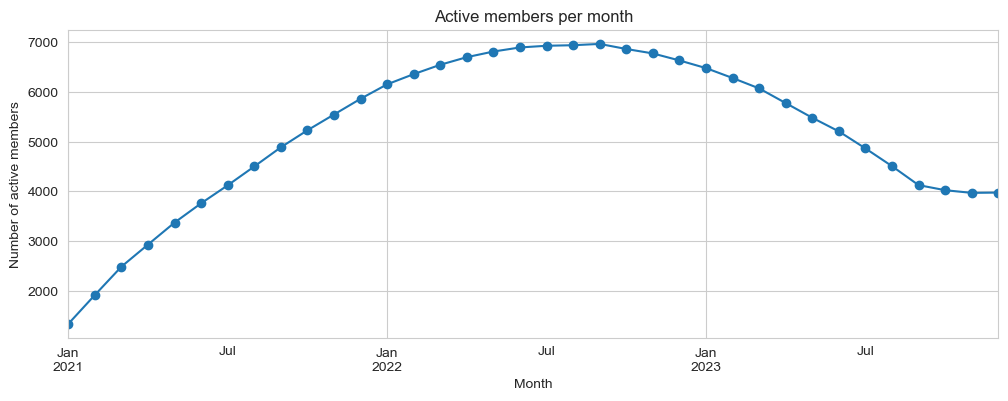

2023-12    3976
Freq: M, dtype: int64
Peak: 2022-09 6964
Months with more members leaving than joining: ['2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11']


In [13]:
months = pd.period_range(df["membership_start"].min().to_period("M"),
                         pd.Timestamp("2023-12-01").to_period("M"), freq="M")

joined = df.groupby(df["membership_start"].dt.to_period("M")).size().reindex(months, fill_value=0)
left_m = (df.dropna(subset=["membership_end"])
            .groupby(df["membership_end"].dt.to_period("M")).size()
            .reindex(months, fill_value=0))

active_per_month = (joined - left_m).cumsum()

active_per_month.plot(figsize=(12, 4), marker="o")
plt.title("Active members per month")
plt.xlabel("Month")
plt.ylabel("Number of active members")
plt.show()

print(active_per_month.tail(1))
print("Peak:", active_per_month.idxmax(), active_per_month.max())
print("Months with more members leaving than joining:", list((left_m > joined)[lambda s: s].index.astype(str)))

Active members grow steadily from January 2021 to a peak of 6,964 in September 2022, and then decline through 2023.

By the end of December 2023 we have 3,976 active members (3,902 after the 74 members who left on the extraction date, 2024-01-01). From October 2022 to November 2023, more members left than joined in every month.

We should read this with care: members who left before 2021 are not in the data, so the growth of 2021 is overstated, and the change at the end of 2023 needs to be confirmed with ACDC (see the cohorts below).

### 5.3. Members leaving per month

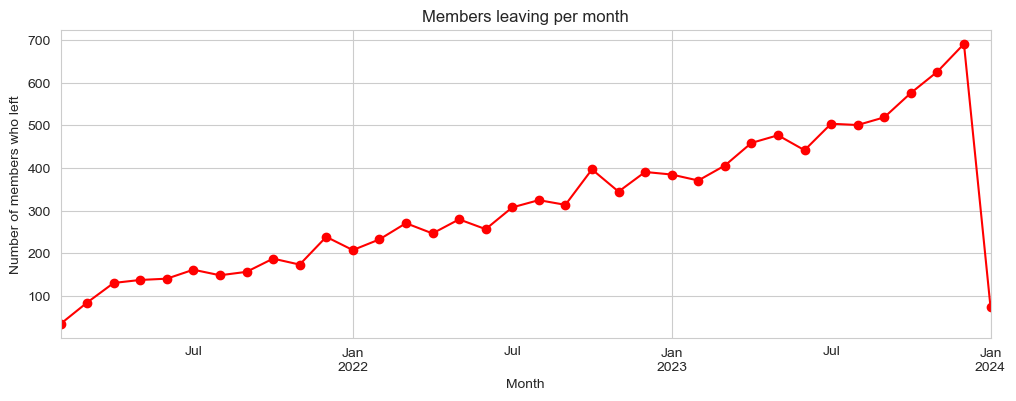

Members who left on the extraction date (January 2024 has only this day): 74


In [14]:
left = df.dropna(subset=["membership_end"])
left_per_month = left.groupby(left["membership_end"].dt.to_period("M")).size()

left_per_month.plot(figsize=(12, 4), marker="o", color="red")
plt.title("Members leaving per month")
plt.xlabel("Month")
plt.ylabel("Number of members who left")
plt.show()

print("Members who left on the extraction date (January 2024 has only this day):", left_per_month.loc["2024-01"])

The number of members leaving per month increases gradually through the period. Part of this is expected, because there are more members who can leave as the base grows, and members who left before 2021 are not in the data.

The drop at the end of the chart is not a real change: January 2024 has only one day of data, the extraction date.

### 5.4. Days with membership

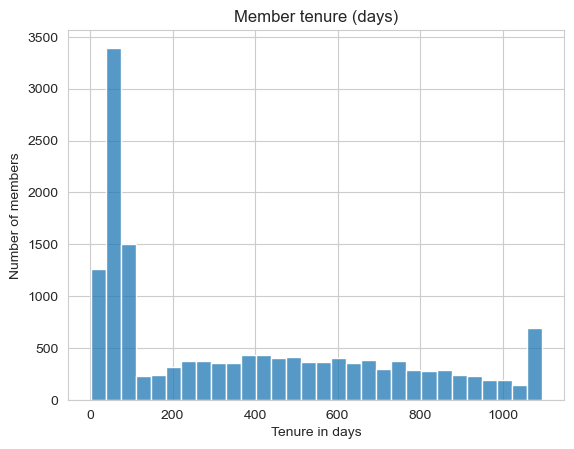

count    15108.000000
mean       374.094586
std        338.607673
min          2.000000
25%         65.000000
50%        282.000000
75%        635.000000
max       1095.000000
Name: tenure_days, dtype: float64


In [15]:
extraction_date = pd.Timestamp("2024-01-01")
end = df["membership_end"].fillna(extraction_date)
df["tenure_days"] = (end - df["membership_start"]).dt.days

sns.histplot(df["tenure_days"], bins=30)
plt.title("Member tenure (days)")
plt.xlabel("Tenure in days")
plt.ylabel("Number of members")
plt.show()

print(df["tenure_days"].describe())

The mean member tenure is 374 days, and there is a lot of deviation between the values.

75% of the members stayed up to 635 days, and only 25% stayed 635 days or more. Half of the members stayed up to 282 days.

### 5.5. Member cohorts

In [16]:
df["cohort"] = df["membership_start"].dt.to_period("Q").astype(str)
df["is_premium"] = df["plan_tier"].isin(["dedicated_desk", "private_office"])

cohort_summary = df.groupby("cohort").agg(
    members=("member_id", "count"),
    churn_rate=("membership_end", lambda s: s.notna().mean()),
    median_tenure_days=("tenure_days", "median"),
    mean_ltv=("lifetime_value", "mean"),
    premium_share=("is_premium", "mean"),
).round(2)
print(cohort_summary)

        members  churn_rate  median_tenure_days  mean_ltv  premium_share
cohort                                                                  
2021Q1     2607        0.73               825.0   9436.34           0.35
2021Q2     1684        0.87               527.5   5918.45           0.20
2021Q3     1593        0.83               511.0   5284.87           0.16
2021Q4     1576        0.79               469.0   4410.40           0.14
2022Q1     1396        0.81               399.0   3679.07           0.11
2022Q2     1132        0.81               327.0   2941.09           0.08
2022Q3     1018        0.84               227.0   2052.17           0.05
2022Q4      801        0.87               101.0   1501.76           0.04
2023Q1      600        0.97                79.0    862.02           0.00
2023Q2      514        0.96                71.0    574.76           0.00
2023Q3      444        0.96                64.0    392.97           0.00
2023Q4     1743        0.10                38.0    

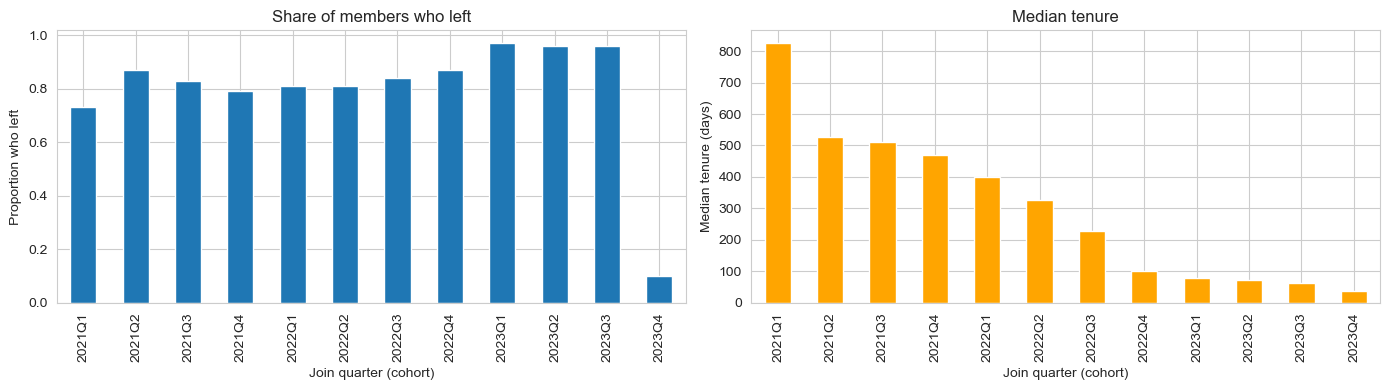

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

cohort_summary["churn_rate"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Share of members who left")
axes[0].set_xlabel("Join quarter (cohort)")
axes[0].set_ylabel("Proportion who left")

cohort_summary["median_tenure_days"].plot(kind="bar", ax=axes[1], color="orange")
axes[1].set_title("Median tenure")
axes[1].set_xlabel("Join quarter (cohort)")
axes[1].set_ylabel("Median tenure (days)")

plt.tight_layout()
plt.show()

Older cohorts stay a lot longer: the median tenure and the average lifetime value drop in each newer cohort. We must keep in mind that recent cohorts have had less time to stay and accumulate value.

The share of members who left is high in every cohort except 2023Q4, because most of those members joined only a few weeks before the extraction date.

The cohorts from 2023Q1 to 2023Q3 look unusual: 96% to 97% of their members have already left, and the share of premium plans (`dedicated_desk`, `private_office`) falls to 0% or close to it, before returning in 2023Q4. This sudden change could come from the way the data was built, so it should be confirmed with ACDC before being presented as real behaviour.

## 6. Numeric relationships

In [18]:
# tenure_days now exists, so we update the list (is_premium is a flag, so it stays out of it)
metric_features = df.select_dtypes(include="number").columns.tolist()

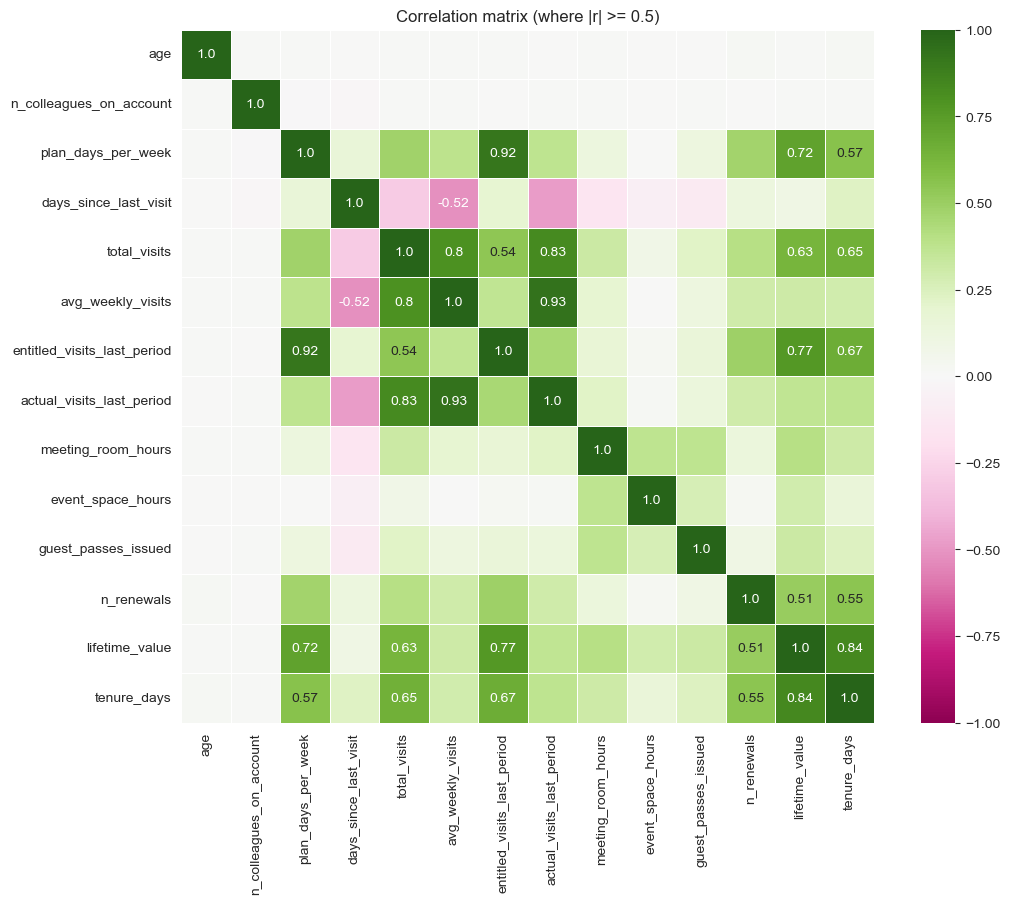

In [19]:
corr = df[metric_features].corr().round(2)

# annotate only the strong values, as in lab04
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=np.where(corr.abs() >= 0.5, corr.values, ""), fmt="s",
            cmap="PiYG", center=0, vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Correlation matrix (where |r| >= 0.5)")
plt.show()

Only correlations with |r| >= 0.5 are annotated, to keep the heatmap readable.

There are two separate groups of strong correlations. Visit variables go together: `actual_visits_last_period` with `avg_weekly_visits` (0.93) and `total_visits` (0.83). The plan variables go together: `plan_days_per_week` with `entitled_visits_last_period` (0.92). Between the two groups the correlation is weak or moderate (0.37 between `plan_days_per_week` and `actual_visits_last_period`), so having more days available does not mean coming more.

`lifetime_value` is strongly correlated with `tenure_days` (0.84), while age, team size, meeting room, event space and guest pass usage show no strong linear relationships with the other variables.

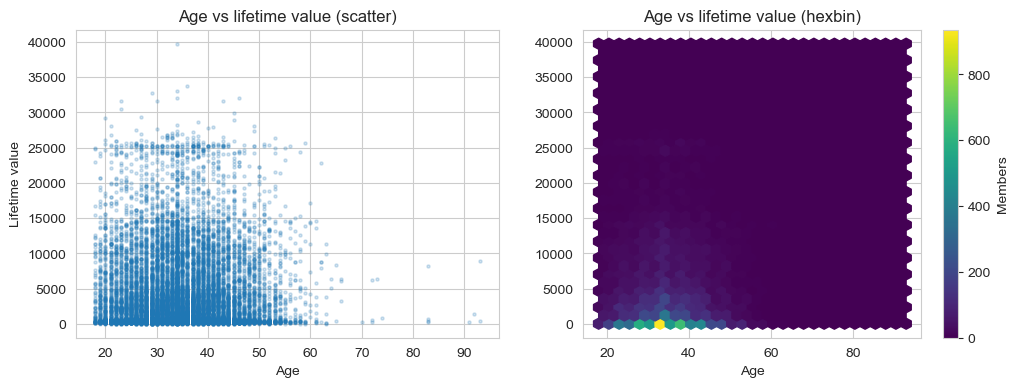

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df["age"], df["lifetime_value"], alpha=0.2, s=5)
axes[0].set_title("Age vs lifetime value (scatter)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Lifetime value")

hb = axes[1].hexbin(df["age"], df["lifetime_value"], gridsize=30, cmap="viridis")
axes[1].set_title("Age vs lifetime value (hexbin)")
axes[1].set_xlabel("Age")
fig.colorbar(hb, ax=axes[1], label="Members")
plt.show()

Age and lifetime value don't seem to be correlated. Members of all ages have very different values. The highest concentration is between ages 25 and 45 with a low lifetime value, and there are very few members above 60.

This makes sense: the heatmap shows that age has no strong correlation with the other variables.

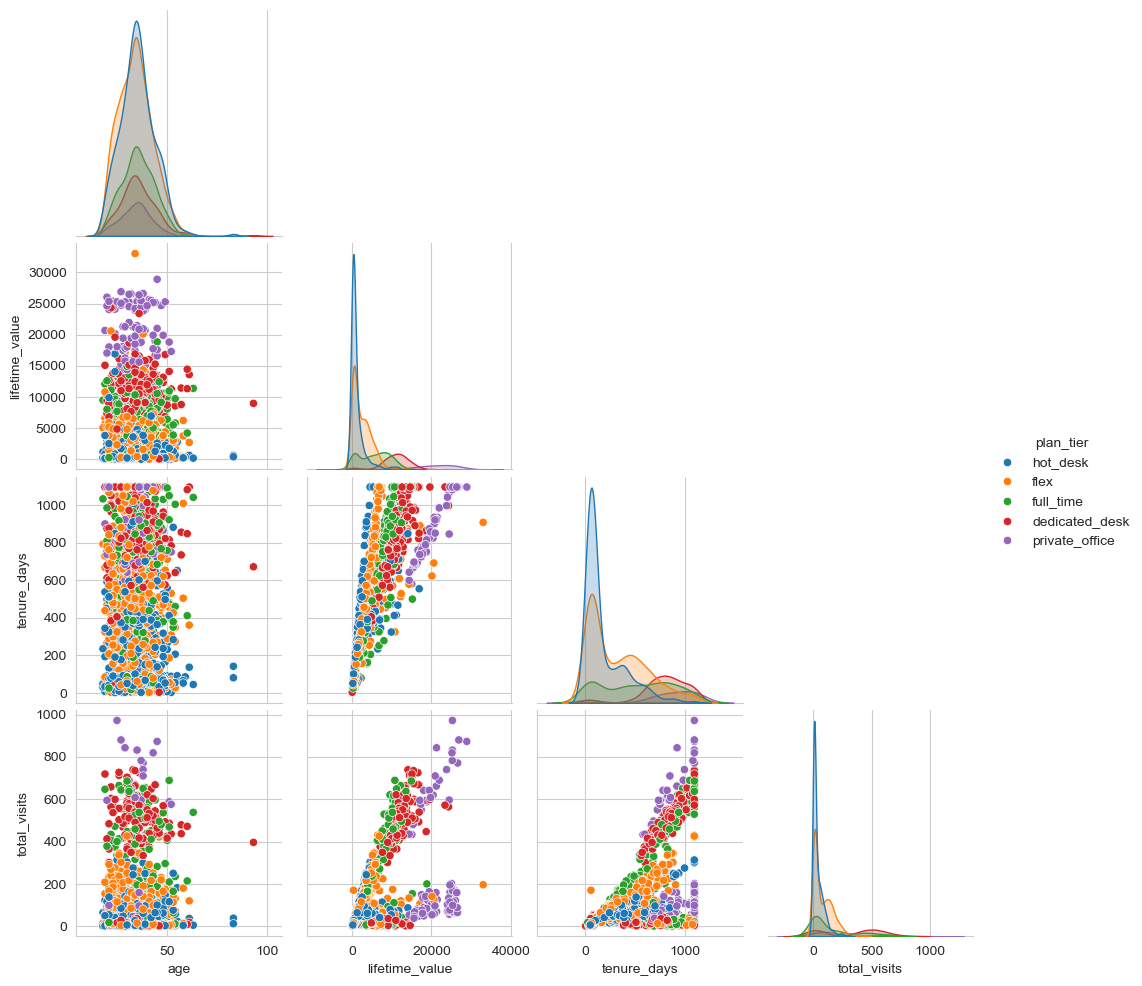

In [21]:
cols = ["age", "lifetime_value", "tenure_days", "total_visits", "plan_tier"]
sns.pairplot(df[cols].sample(2000, random_state=1),
             hue="plan_tier", hue_order=p_order, corner=True)
plt.show()

This pair plot shows that the plan tier separates members mainly by lifetime value and tenure days.

As expected, hot desk and flex concentrate on low values, while dedicated desk and private office reach the highest values.


## 7. Plan profiles

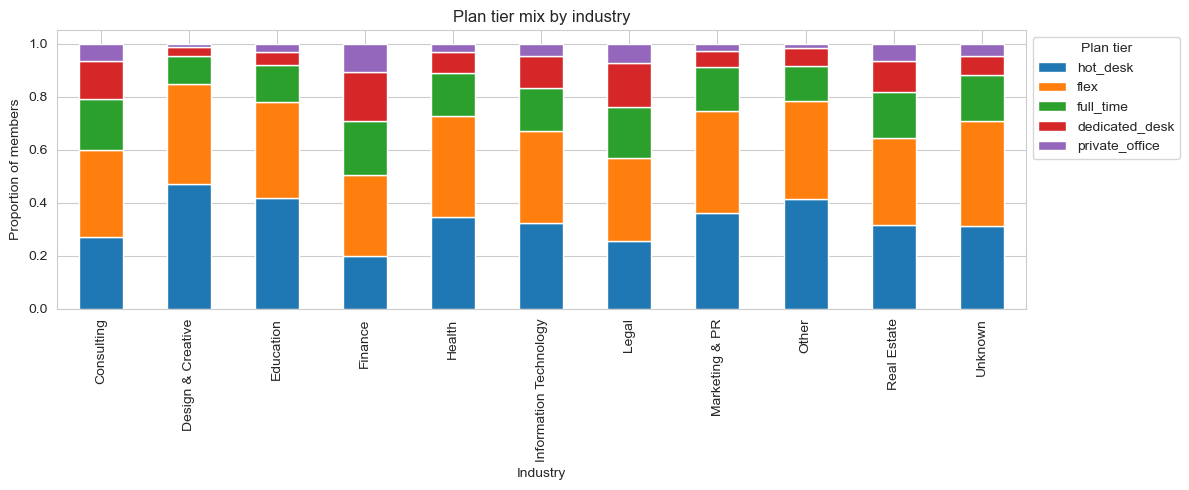

% in dedicated_desk or private_office:
industry
Design & Creative          4.8
Education                  7.9
Other                      8.6
Marketing & PR             8.8
Health                    11.0
Unknown                   12.0
Information Technology    16.7
Real Estate               18.3
Consulting                21.0
Legal                     23.9
Finance                   29.1


In [22]:
ct = pd.crosstab(df["industry"], df["plan_tier"], normalize="index")[p_order]
ct.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Plan tier mix by industry")
plt.xlabel("Industry")
plt.ylabel("Proportion of members")
plt.legend(title="Plan tier", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print("% in dedicated_desk or private_office:")
print((ct[["dedicated_desk", "private_office"]].sum(axis=1) * 100).round(1).sort_values().to_string())

Design & Creative and Education have less expensive plans (hot desk at about 45%), and only 4.8% and 7.9% of their members have a premium plan.

On the other hand, Finance and Legal have higher tier plans (29.1% and 23.9% in private office or dedicated desk).

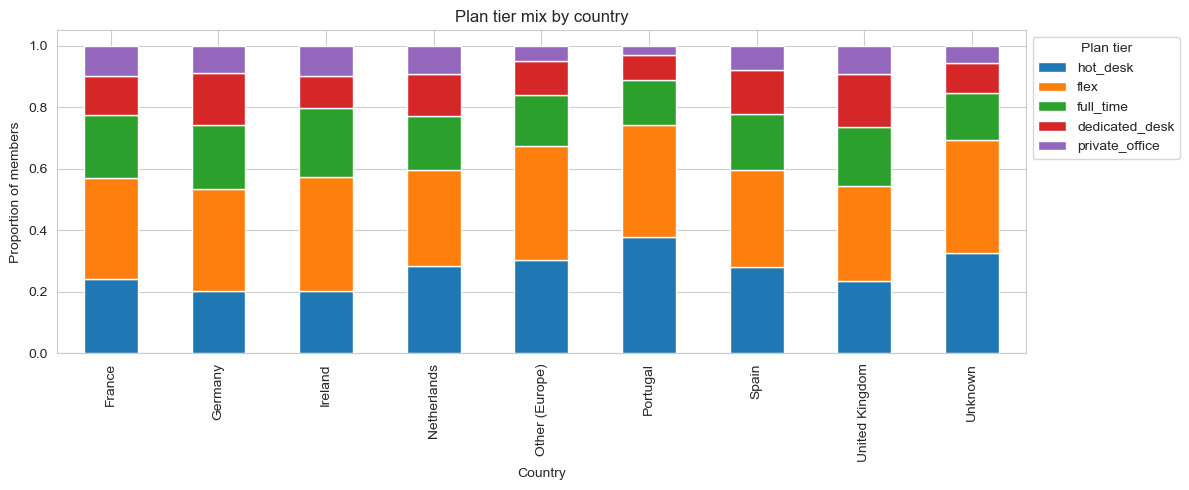

% in hot_desk or flex: {'Germany': 53.5, 'United Kingdom': 54.3, 'France': 57.2, 'Ireland': 57.4, 'Netherlands': 59.5, 'Spain': 59.7, 'Other (Europe)': 67.3, 'Unknown': 69.5, 'Portugal': 74.2}
% in dedicated_desk or private_office:
country
Portugal          11.0
Unknown           15.5
Other (Europe)    15.9
Ireland           20.3
Spain             22.1
France            22.6
Netherlands       22.9
Germany           25.7
United Kingdom    26.2


In [23]:
ct = pd.crosstab(df["country"], df["plan_tier"], normalize="index")[p_order]
ct.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Plan tier mix by country")
plt.xlabel("Country")
plt.ylabel("Proportion of members")
plt.legend(title="Plan tier", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print("% in hot_desk or flex:", (ct[["hot_desk", "flex"]].sum(axis=1) * 100).round(1).sort_values().to_dict())
print("% in dedicated_desk or private_office:")
print((ct[["dedicated_desk", "private_office"]].sum(axis=1) * 100).round(1).sort_values().to_string())

Portugal has the highest percentage of low-cost plans (74.2% in hot desk or flex) and the lowest of premium plans (11.0%). The United Kingdom and Germany have the most members in dedicated desk and private office (26.2% and 25.7%).

## 8. Redundant variables

In [24]:
corr_abs = df[metric_features].corr().abs()
pairs = (corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False))
print(pairs[pairs > 0.8])

avg_weekly_visits   actual_visits_last_period      0.932189
plan_days_per_week  entitled_visits_last_period    0.917123
lifetime_value      tenure_days                    0.844128
total_visits        actual_visits_last_period      0.826656
                    avg_weekly_visits              0.800994
dtype: float64


These are the five pairs of variables with a correlation above 0.8.

They form three groups:

- **Visit frequency:** `avg_weekly_visits`, `actual_visits_last_period`, `total_visits`. These are redundant, although they cover different periods, so we would keep `avg_weekly_visits`, which does not depend on the length of the membership.
- **Contracted days:** `plan_days_per_week`, `entitled_visits_last_period`. These are redundant, and keeping one is enough.
- **Value:** `lifetime_value`, `tenure_days`. These are correlated because revenue accumulates with time, but they measure different things, so we would not simply drop one. It is better to use `tenure_days` together with a rate such as `ltv_per_month`.

The final choice should be made before clustering, also considering the features created in the behaviour analysis.

#### Implications for clustering

Our descriptive analysis shows that the ACDC member base is quite homogeneous in age and gender (median age of 34 in every plan, partly an effect of the imputation, and about half of the members are women). The country is mostly Portugal, but it is related to the plan, so it may help to profile the segments even if it should not build them.

On the other hand, behaviour and value differ. Lifetime value rises with plan tier, while visits don't (private office members pay the most but have a median of only 133 visits, against 396 for dedicated desk).

Tenure and cohorts also point to distinct profiles, with short stays on one side and long-term members on the other.

Several variables are redundant, so we have to make that decision before clustering.

Together, these findings suggest that clusters will be driven by usage, plan value and tenure rather than by demographics.

We should also be careful about observation-window effects, so that they are not mistaken for real segments.